# Active subspaces of the Doyle–Fuller–Newman battery model under a scaled US06 drive cycle

Model and parameter study from: E. Zonta, I. Jovanovic Buha, M. Spinola, C. Weißinger, H.-J. Bungartz, A. Jossen, "Time-dependent global sensitivity analysis of the Doyle–Fuller–Newman model", *Journal of Energy Storage* 158 (2026) 121751, [doi:10.1016/j.est.2026.121751](https://doi.org/10.1016/j.est.2026.121751).

__Elia Zonta__, __Andreas Jossen__: Technical University of Munich, School of Engineering and Design, Department of Energy and Process Engineering, Chair of Electrical Energy Storage Technology, Munich, Germany

__Ivana Jovanovic Buha__, __Hans-Joachim Bungartz__: Technical University of Munich, School of Computation, Information and Technology, Department of Computer Science, Chair of Scientific Computing, Garching, Germany

__Michele Spinola__, __Christoph Weißinger__: Capgemini Engineering, Center of Excellence Battery, Munich, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

(Affiliations as in the arXiv version, arXiv:2502.17275v2, which is the version read for this notebook; the citation is the published article.)

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import active_subspaces as ac
import dfn_us06 as dfn          # constants only; running the model needs PyBaMM (see DATA.md)

SEED = 2026

## Summary

We ran the Doyle–Fuller–Newman (DFN) lithium-ion cell model of Zonta et al. (PyBaMM 24.9.0, Marquis et al. parameter set, a scaled US06 drive cycle) at 650 Monte Carlo samples of the paper's 24 uncertain parameters (Table A.2), recording the terminal voltage every second for 600 s, and for the time-averaged voltage and the end-of-cycle voltage we estimate active subspaces from the values with a global quadratic model (QPHD), cross-checked with global linear and local linear estimates. The time-averaged voltage has one leading direction, made up mostly of the positive electrode's electronic conductivity and solid diffusivity, with $\lambda_1/\lambda_2 \approx 5$ (bootstrap range 2.2–5.5) and a second gap of similar size, so the choice $n = 1$ rests on the robustness of that direction (it is stable under regularization, data splits and a change of estimator), and a one-variable surrogate predicts $\bar U$ with leave-one-out $R^2 \approx 0.7$ (0.75 with two variables). This disagrees with the paper's Sobol' analysis, which finds those two inputs negligible and ranks the positive electrode's thickness, porosity, particle radius and capacity first; the disagreement is the same at 116 runs as at 650, and the authors' TDGSA code suggests two possible, unconfirmed causes, both acting on the log-uniform inputs (how the bounds reach chaospy's log-uniform distribution, and a polynomial chaos basis in physical rather than log units), which we list as questions for the authors.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x$; if the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along $\mathbf W_1^T\mathbf x$ and is nearly constant along the other directions. Without gradients, $\mathbf C$ can be estimated from values: a global quadratic model $q(\mathbf x) = c + \mathbf g^T\mathbf x + \frac12\mathbf x^T\mathbf H\mathbf x$ fitted by least squares gives $\mathbf C \approx \mathbb E[\nabla q\,\nabla q^T] = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ (QPHD); a global linear model gives one direction (a one-dimensional subspace only); and local linear fits on nearest neighbours give approximate gradients whose outer products estimate $\mathbf C$. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

The DFN (pseudo-two-dimensional) model describes a cell as a negative electrode, a separator and a positive electrode, each a porous medium filled with electrolyte, with spherical particles in the electrodes. Zonta et al. (Section 2.2, Eqs. (23)–(42)) write it, following PyBaMM's conventions, as charge conservation in the electrolyte and the solid,

$$\frac{\partial i_{l,k}}{\partial x} = a_k j_k,\qquad i_{l,k} = \epsilon_k^{b_k}\kappa\left(-\frac{\partial \phi_{l,k}}{\partial x} + 2\Theta(1-t^+)\frac{RT}{F}\frac{\partial \ln c_{l,k}}{\partial x}\right),\qquad I - i_{l,k} = -\sigma_k\frac{\partial\phi_{s,k}}{\partial x},$$

mass conservation in the electrolyte and in the particles,

$$\epsilon_k\frac{\partial c_{l,k}}{\partial t} = \frac{\partial}{\partial x}\left(\epsilon_k^{b_k} D_l \frac{\partial c_{l,k}}{\partial x}\right) + \frac{1-t^+}{F}\frac{\partial i_{l,k}}{\partial x},\qquad \frac{\partial c_{s,k}}{\partial t} = \frac{1}{r_k^2}\frac{\partial}{\partial r_k}\left(r_k^2 D_{s,k}\frac{\partial c_{s,k}}{\partial r_k}\right),$$

and Butler–Volmer kinetics with exchange current density $j_{0,k} = F k_{0,k}\, c_{s,k}^{1/2}(c_{s,k}^{\max}-c_{s,k})^{1/2} c_{l,k}^{1/2}$ at the particle surface. The specific surface area is $a_k = 3\epsilon_{s,k}/R_k$ with $\epsilon_{s,k} = 1-\epsilon_{l,k}$ (the paper's simplification, Section 3.3.1). The model is isothermal at 298.15 K.

**Implementation** (`dfn_us06.py`, run with PyBaMM 24.9.0; see `DATA.md` for every setting). PyBaMM's DFN with its default mesh (20 points in each subdomain in $x$ and in $r$), the CasADi solver in "fast" mode at tolerances $10^{-6}$, and the `Marquis2019` parameter set (Kokam SLPB78205130H) for everything that is not sampled: open-circuit potentials, electrode area $0.137 \times 0.207$ m², temperature. The 24 inputs below overwrite the corresponding PyBaMM entries as scalars (no concentration dependence). The initial particle concentrations are $c_{s,k}^{\max}/2$, so every sample starts at the same voltage (Eq. (44)).

**Drive cycle.** The current is PyBaMM's US06 profile (601 points, 1 Hz, as shipped with PyBaMM up to v24.1 and in the authors' TDGSA repository), multiplied by one factor for all samples. The paper chooses the factor "such that the peak $C_\mathrm{theo}$-rate does not exceed 2 h⁻¹" (Section 3.3.2), with the theoretical limiting capacity $C_\mathrm{theo} = \min_k F c_{s,k}^{\max} L_k \epsilon_{s,k}$. **Choice made here, not stated in the paper (a question for the authors):** we take the smallest $C_\mathrm{theo}$ in the box of Table A.2 (positive electrode at its smallest $c^{\max}$ and $L$ and largest porosity, 1.353 A h m⁻²), so the peak current density is 2.706 A m⁻² and the factor on the US06 current is 0.009473. The paper's Fig. 6e shows a peak of about 2.85 A m⁻² (read from the figure), so its factor was about 5 % larger; the exact value is not stated. A difference of this size cannot reorder the inputs (see the comparison with the paper).

**Quantities of interest.** The paper analyses the whole voltage curve $U(t)$, $t \in [0, 600]$ s, with generalized Sobol' indices. We use two scalars: the time-averaged terminal voltage $\bar U = \frac{1}{600}\int_0^{600} U\,dt$ (trapezoidal rule on the 1-s grid, the same quadrature the paper uses for its time integrals) and the end-of-cycle voltage $U(600\,\mathrm s)$, and at the end look at $U(t)$ at five times.

**Overlap with `energy/Lithium_Ion_Battery`.** That data set (Constantine & Doostan 2017, from Hadigol et al.'s runs) is also a Newman-type model with time-dependent active subspaces, but for a LiC₆/LiCoO₂ cell under constant-current discharge at three C-rates, with 19 inputs and a different code. This one is new in its implementation (PyBaMM), cell parameterisation (Marquis/Kokam), inputs (24, with literature-wide ranges from LiionDB, seven of them log-uniform; the uniform ones include the electrode thicknesses and particle radii), and load (a dynamic drive cycle starting at half charge).

**Inputs.** Independent, uniform or log-uniform on the ranges of Table A.2 (p. 18). We work in coordinates $z_j = x_j$ for uniform inputs and $z_j = \log_{10} x_j$ for log-uniform ones, in which every input is uniform; v1 then maps each $z_j$ linearly to $[-1, 1]$. Every input is thus scaled the same way, through its own CDF. The table is printed from the model code:

In [2]:
rows = ['| # | name | symbol | units | lower | upper | distribution (Table A.2) |', '|---|---|---|---|---|---|---|']
for j, (name, sym, unit, lo, hi, dist) in enumerate(dfn.INPUTS):
    rows.append(f'| {j} | `{name}` | {sym} | {unit} | {lo:.3g} | {hi:.3g} | {dist} |')
display(Markdown('\n'.join(rows)))
print(f'm = {len(dfn.NAMES)} inputs, {dfn.LOG.sum()} log-uniform; current factor on US06 = {dfn.SCALE:.6f}, '
      f'peak current density {dfn.PEAK_CURRENT_DENSITY:.3f} A/m^2, C_theo,min in the box {dfn.C_THEO_MIN:.3f} A h/m^2')

| # | name | symbol | units | lower | upper | distribution (Table A.2) |
|---|---|---|---|---|---|---|
| 0 | `cs_max_pos` | c_s,pos^max | mol m^-3 | 2.39e+04 | 5.18e+04 | uniform |
| 1 | `L_pos` | L_pos | m | 6e-06 | 6.6e-05 | uniform |
| 2 | `eps_pos` | eps_l,pos | - | 0.171 | 0.648 | uniform |
| 3 | `R_pos` | R_pos | m | 5e-07 | 1e-05 | uniform |
| 4 | `k0_pos` | k_0,pos | m^2.5 mol^-0.5 s^-1 | 2.1e-12 | 2.41e-05 | loguniform |
| 5 | `Ds_pos` | D_s,pos | m^2 s^-1 | 9.59e-19 | 2.51e-12 | loguniform |
| 6 | `sigma_pos` | sigma_pos | S m^-1 | 5.2e-06 | 1e+03 | loguniform |
| 7 | `b_pos` | b_pos | - | 1.44 | 2.44 | uniform |
| 8 | `cs_max_neg` | c_s,neg^max | mol m^-3 | 1.61e+04 | 3.19e+04 | uniform |
| 9 | `L_neg` | L_neg | m | 4.6e-05 | 7.2e-05 | uniform |
| 10 | `eps_neg` | eps_l,neg | - | 0.26 | 0.5 | uniform |
| 11 | `R_neg` | R_neg | m | 1e-05 | 1.26e-05 | uniform |
| 12 | `k0_neg` | k_0,neg | m^2.5 mol^-0.5 s^-1 | 1e-11 | 0.003 | loguniform |
| 13 | `Ds_neg` | D_s,neg | m^2 s^-1 | 2e-16 | 9.07e-12 | loguniform |
| 14 | `sigma_neg` | sigma_neg | S m^-1 | 0.111 | 2.2e+03 | loguniform |
| 15 | `b_neg` | b_neg | - | 1.5 | 4.1 | uniform |
| 16 | `L_sep` | L_sep | m | 1.6e-05 | 5e-05 | uniform |
| 17 | `eps_sep` | eps_l,sep | - | 0.37 | 0.6 | uniform |
| 18 | `b_sep` | b_sep | - | 1.5 | 2.57 | uniform |
| 19 | `Theta` | Theta | - | 1 | 1.86 | uniform |
| 20 | `c_l0` | c_l,0 | mol m^-3 | 500 | 1.5e+03 | uniform |
| 21 | `D_l` | D_l | m^2 s^-1 | 3.6e-11 | 1.09e-09 | loguniform |
| 22 | `kappa` | kappa | S m^-1 | 0.00445 | 2.45 | uniform |
| 23 | `t_plus` | t+ | - | -0.37 | 0.51 | uniform |

m = 24 inputs, 7 log-uniform; current factor on US06 = 0.009473, peak current density 2.706 A/m^2, C_theo,min in the box 1.353 A h/m^2


## Load the data

`inputs.csv` holds the 650 input vectors in physical units (an i.i.d. Monte Carlo design, seed 20261031 in `generate_data.py`), `outputs.csv` a status flag, $\bar U$, $U(600)$ and the run time, and `voltage.csv` the voltage at $t = 0, 1, \dots, 600$ s. A failed run would be kept in the files with status 0 and NaN outputs; the rule here is to drop rows with status 0. This cell is also where the inputs are converted, once, to the coordinates $z$.

inputs (650, 24), outputs (650, 4), voltage (650, 601); failed runs: 0 of 650
M = 650, m = 24; run time per sample: median 5.2 s, range 1.6-27.2 s, total 71 min
U(0) = 3.9906 V for every sample (std 8.2e-05 V); mean U_bar = 3.9580 V, std 0.0460 V; mean U(600) = 3.9544 V, std 0.0532 V
voltage range over all runs and times: 3.362-4.125 V; lowest U_bar: 3.700 V


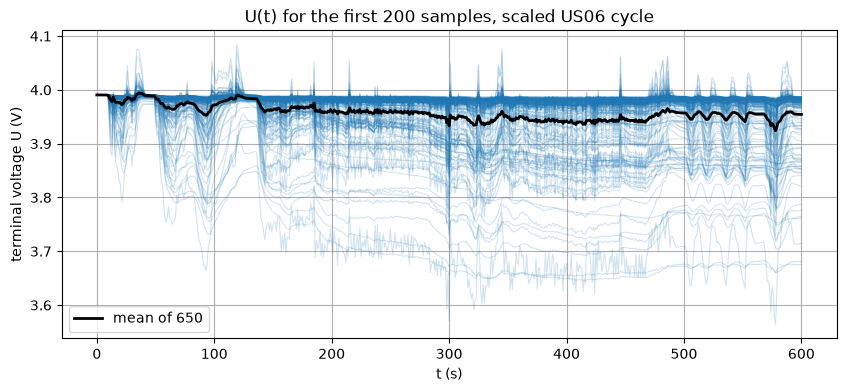

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')            # (M, 24) physical units
out = np.loadtxt('outputs.csv', delimiter=',')         # status, V_mean, V_end, run time
V = np.loadtxt('voltage.csv', delimiter=',')           # (M, 601) U(t) at t = 0..600 s
t = np.arange(V.shape[1], dtype=float)
ok = out[:, 0] == 1
print(f'inputs {X.shape}, outputs {out.shape}, voltage {V.shape}; failed runs: {(~ok).sum()} of {len(ok)}')
X, V, f_mean, f_end, run_s = X[ok], V[ok], out[ok, 1], out[ok, 2], out[ok, 3]

to_z = lambda x: np.where(dfn.LOG, np.log10(np.where(dfn.LOG, x, 1.0)), x)   # the one conversion: log10 for log-uniform inputs
Z = to_z(X)
space = ac.Uniform(to_z(dfn.LOWER), to_z(dfn.UPPER), names=dfn.NAMES)
labels = [r'$c^{max}_{s,pos}$', r'$L_{pos}$', r'$\epsilon_{l,pos}$', r'$R_{pos}$', r'$\log k_{0,pos}$',
          r'$\log D_{s,pos}$', r'$\log \sigma_{pos}$', r'$b_{pos}$', r'$c^{max}_{s,neg}$', r'$L_{neg}$',
          r'$\epsilon_{l,neg}$', r'$R_{neg}$', r'$\log k_{0,neg}$', r'$\log D_{s,neg}$', r'$\log \sigma_{neg}$',
          r'$b_{neg}$', r'$L_{sep}$', r'$\epsilon_{l,sep}$', r'$b_{sep}$', r'$\Theta$', r'$c_{l,0}$',
          r'$\log D_l$', r'$\kappa$', r'$t^+$']
M, m = Z.shape
print(f'M = {M}, m = {m}; run time per sample: median {np.median(run_s):.1f} s, range {run_s.min():.1f}-{run_s.max():.1f} s, '
      f'total {run_s.sum() / 60:.0f} min')
print(f'U(0) = {V[:, 0].mean():.4f} V for every sample (std {V[:, 0].std():.1e} V); '
      f'mean U_bar = {f_mean.mean():.4f} V, std {f_mean.std():.4f} V; mean U(600) = {f_end.mean():.4f} V, std {f_end.std():.4f} V')
print(f'voltage range over all runs and times: {V.min():.3f}-{V.max():.3f} V; lowest U_bar: {f_mean.min():.3f} V')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, V[:200].T, color='C0', alpha=0.2, lw=0.8)
ax.plot(t, V.mean(0), color='k', lw=2, label=f'mean of {M}')
ax.set_xlabel('t (s)'); ax.set_ylabel('terminal voltage U (V)'); ax.legend(); ax.grid(True)
ax.set_title('U(t) for the first 200 samples, scaled US06 cycle')
plt.close(fig)
fig

## Estimate the subspace

**Choice of estimator.** There are no gradients: finite differences would need $m + 1 = 25$ runs per gradient at about 5 s per run (median printed above), so even 300 gradients would take about 10 hours on one core. With $M = 650$ runs the global quadratic estimator (QPHD) is usable: it needs $M \ge (m+1)(m+2)/2 = 325$, and the repository's rule asks for twice that, 650. It is the headline estimator here. Two caveats: v1 warns that its justification (Stein's lemma) is exact for Gaussian inputs, not for the uniform cube; and a full quadratic in 24 variables has 325 coefficients, so with 650 points the fit is only partly determined (its leave-one-out $R^2$ is printed below). We therefore cross-check its directions with

- **global linear least squares** (`estimator="ols"`, one direction), and
- **outer products of local linear gradients** (`estimator="opg"`, $p = 40$ nearest neighbours per fit).

All use 200 bootstrap replicates (QPHD and OPG) with the seed above, and the eigenvalue-gap rule of v1 picks $n$.

In [4]:
import warnings

def top(w, k=6):
    return ', '.join(f'{dfn.NAMES[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:k])

def estimate(f, qoi):
    q = ac.active_subspace(space=space, X=Z, f=f, estimator='qphd', nboot=200, rng=SEED, qoi=qoi)
    q = ac.orient(q, by='covariance', X=Z, f=f, columns=2)           # U increases along w1 and w2
    o = ac.active_subspace(space=space, X=Z, f=f, estimator='ols', qoi=qoi)
    g = ac.active_subspace(space=space, X=Z, f=f, estimator='opg', nboot=200, rng=SEED, qoi=qoi)
    return q, o, g

ju, ku = np.triu_indices(m, k=1)
A_quad = np.column_stack([np.ones(M), space.to_normalized(Z), space.to_normalized(Z) ** 2,
                          space.to_normalized(Z)[:, ju] * space.to_normalized(Z)[:, ku]])   # monomials of v1's QPHD

def quad_parts(c):
    # gradient g and Hessian H of q(x) = c0 + g^T x + x^T H x / 2 from the coefficients on A_quad
    H = np.diag(2.0 * c[m + 1:2 * m + 1])
    H[ju, ku] = H[ku, ju] = c[2 * m + 1:]
    return c[1:m + 1], H

def quadratic_fit(f):
    # the least-squares quadratic QPHD is built on, in normalized coordinates; R^2, leave-one-out R^2, coefficients
    A = A_quad
    c, *_ = np.linalg.lstsq(A, f, rcond=None)
    r = f - A @ c
    h = np.einsum('ij,ji->i', A, np.linalg.pinv(A))
    return A.shape[1], 1 - r.var() / f.var(), 1 - np.mean((r / (1 - h)) ** 2) / f.var(), c

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)          # the Gaussian-inputs caveat, discussed above
    q_mean, ols_mean, opg_mean = estimate(f_mean, 'U_bar')
    q_end, ols_end, opg_end = estimate(f_end, 'U_600')

for name, q, o, g, f in [('U_bar', q_mean, ols_mean, opg_mean, f_mean), ('U(600)', q_end, ols_end, opg_end, f_end)]:
    lam = q.eigenvalues
    p, r2, loo, c = quadratic_fit(f)
    print(f'{name}: QPHD lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
          f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}; share of trace in lambda_1 = {lam[0] / lam.sum():.2f}; rule picks n = {q.n}')
    print(f'   QPHD w1: {top(q.W[:, 0])}')
    print(f'   QPHD w2: {top(q.W[:, 1])}')
    print(f'   |w1 . w_OLS| = {abs(q.W[:, 0] @ o.W[:, 0]):.3f}, |w1 . w1_OPG| = {abs(q.W[:, 0] @ g.W[:, 0]):.3f}; '
          f'OPG lambda_1/lambda_2 = {g.eigenvalues[0] / g.eigenvalues[1]:.2f}, lambda_2/lambda_3 = {g.eigenvalues[1] / g.eigenvalues[2]:.2f}')
    gq, Hq = quad_parts(c)
    Cg, CH = np.outer(gq, gq), Hq @ space.reference_covariance @ Hq    # C = g g^T + H Sigma H, Sigma = I/3
    wH = np.linalg.eigh(CH)[1][:, -1]
    js = dfn.NAMES.index('sigma_pos')
    print(f'   |weight of sigma_pos|: QPHD w1 {abs(q.W[js, 0]):.2f}, OLS {abs(o.W[js, 0]):.2f}, OPG w1 {abs(g.W[js, 0]):.2f}; '
          f'in C: linear term g/|g| {abs(gq[js]) / np.linalg.norm(gq):.2f}, top eigenvector of the curvature term H Sigma H '
          f'{abs(wH[js]):.2f}; share of trace(C) from g g^T {np.trace(Cg) / np.trace(Cg + CH):.2f}')
    print(f'   quadratic fit ({p} coefficients): R^2 = {r2:.3f}, leave-one-out R^2 = {loo:.3f}')

U_bar: QPHD lambda_1/lambda_2 = 5.07, lambda_2/lambda_3 = 3.48, lambda_3/lambda_4 = 1.36; share of trace in lambda_1 = 0.68; rule picks n = 1
   QPHD w1: sigma_pos +0.89, Ds_pos +0.37, eps_pos -0.17, L_pos +0.08, cs_max_pos +0.08, D_l +0.07
   QPHD w2: L_pos +0.59, Ds_pos +0.57, sigma_pos -0.36, Ds_neg +0.21, eps_pos -0.20, R_pos -0.19
   |w1 . w_OLS| = 0.898, |w1 . w1_OPG| = 0.909; OPG lambda_1/lambda_2 = 7.11, lambda_2/lambda_3 = 1.21
   |weight of sigma_pos|: QPHD w1 0.89, OLS 0.65, OPG w1 0.67; in C: linear term g/|g| 0.71, top eigenvector of the curvature term H Sigma H 0.94; share of trace(C) from g g^T 0.20
   quadratic fit (325 coefficients): R^2 = 0.875, leave-one-out R^2 = 0.464


U(600): QPHD lambda_1/lambda_2 = 1.97, lambda_2/lambda_3 = 5.60, lambda_3/lambda_4 = 1.24; share of trace in lambda_1 = 0.51; rule picks n = 1
   QPHD w1: sigma_pos +0.74, Ds_pos +0.57, eps_pos -0.20, L_pos +0.19, cs_max_pos +0.11, R_pos -0.09
   QPHD w2: sigma_pos -0.59, Ds_pos +0.53, L_pos +0.51, R_pos -0.17, Ds_neg +0.14, k0_pos +0.10
   |w1 . w_OLS| = 0.899, |w1 . w1_OPG| = 0.888; OPG lambda_1/lambda_2 = 4.91, lambda_2/lambda_3 = 1.52
   |weight of sigma_pos|: QPHD w1 0.74, OLS 0.45, OPG w1 0.42; in C: linear term g/|g| 0.55, top eigenvector of the curvature term H Sigma H 0.90; share of trace(C) from g g^T 0.18
   quadratic fit (325 coefficients): R^2 = 0.852, leave-one-out R^2 = 0.359


For $\bar U$ the quadratic estimate has a gap of 5.07 between the first two eigenvalues and of 3.48 between the second and third; the first eigenvalue carries 0.68 of the trace and the gap rule picks $n = 1$. Its first eigenvector is dominated by $\log\sigma_{pos}$ (+0.89) and $\log D_{s,pos}$ (+0.37), with the positive porosity next (−0.17). The three estimators agree on this direction: $|\mathbf w_1^T\mathbf w_{OLS}| = 0.90$ and $|\mathbf w_1^T\mathbf w_{1,OPG}| = 0.91$. QPHD puts more weight on $\log\sigma_{pos}$ (0.89) than OLS (0.65) and OPG (0.67). This comes from the quadratic's curvature term: in $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ the linear term alone gives $\log\sigma_{pos}$ a weight of 0.71, close to OLS, while the curvature term carries 0.80 of the trace (the linear term 0.20) and its leading eigenvector gives $\log\sigma_{pos}$ 0.94. OPG's own $\lambda_1/\lambda_2 = 7.11$ is not a second, independent estimate of the gap: in 24 dimensions, $p = 40$ neighbours out of 650 points make each local fit nearly a semi-global regression, and its $\lambda_2/\lambda_3$ is only 1.21; OPG serves here as a check on $\mathbf w_1$. For $U(600)$ the gap after the first eigenvalue is only 1.97 and the larger gap, 5.60, comes after the second, so $U(600)$ is better described by two directions (the rule still picks $n = 1$, so below we set $n = 2$ for it explicitly). The quadratic that QPHD is built on fits $\bar U$ with $R^2 = 0.87$ but leave-one-out $R^2 = 0.46$ (0.85 and 0.36 for $U(600)$): 325 coefficients from 650 points overfit, so the matrix $\mathbf C$ is noisy. The next cell tests whether that noise affects $\mathbf w_1$.

### Eigenvalues and subspace errors (QPHD, $\bar U$)

bootstrap 95% range of lambda_1/lambda_2: 2.25-5.46 (median 3.61); of lambda_2/lambda_3: 1.05-2.46
mean bootstrap subspace distance, n = 1..4: 0.23, 0.58, 0.92, 0.96


numpy QPHD reproduces v1: lambda_1/lambda_2 = 5.07, |w1 . w1_v1| = 1.0000
ridge penalty   |w1(pen) . w1|   l1/l2   l2/l3   LOO R^2 of the quadratic
      0.1        1.000          5.08    3.50   0.467
      1.0        1.000          5.15    3.67   0.491


      3.0        1.000          5.26    4.01   0.525
     10.0        0.997          5.45    4.81   0.570
     30.0        0.988          5.87    5.30   0.571


    100.0        0.966          7.16    3.94   0.486


pure-noise f on the same X (50 draws): QPHD lambda_1/lambda_2 median 1.19, 95th percentile 1.65


OLS direction on disjoint halves (325 + 325, 50 splits): |w_a . w_b| median 0.92, minimum 0.87


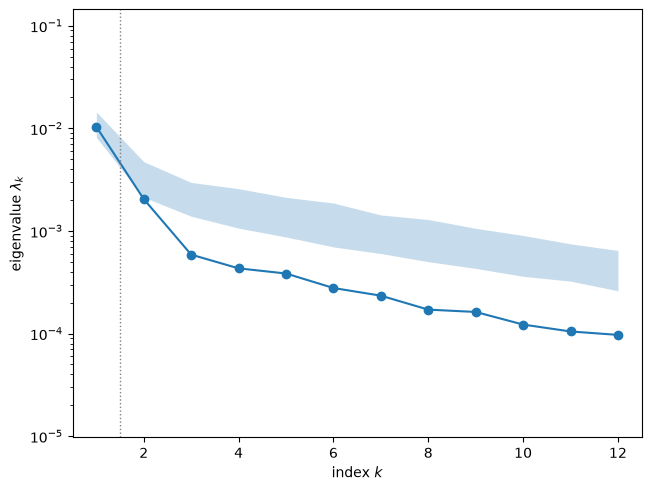

In [5]:
d = q_mean.bootstrap_distances.mean(0)
be = q_mean.bootstrap_eigenvalues
r12, r23 = be[:, 0] / be[:, 1], be[:, 1] / be[:, 2]
print(f'bootstrap 95% range of lambda_1/lambda_2: {np.percentile(r12, 2.5):.2f}-{np.percentile(r12, 97.5):.2f} '
      f'(median {np.median(r12):.2f}); of lambda_2/lambda_3: {np.percentile(r23, 2.5):.2f}-{np.percentile(r23, 97.5):.2f}')
print('mean bootstrap subspace distance, n = 1..4:', ', '.join(f'{v:.2f}' for v in d[:4]))

# Robustness of w1: the same quadratic (A_quad), refitted with a ridge penalty, on pure noise, and OLS on half samples
def qphd_np(f, pen=0.0):
    A = A_quad
    if pen == 0.0:
        c, *_ = np.linalg.lstsq(A, f, rcond=None)
        h = np.einsum('ij,ji->i', A, np.linalg.pinv(A))
    else:
        P = np.eye(A.shape[1]); P[0, 0] = 0.0                     # the intercept is not penalized
        G = A.T @ A + pen * P
        c = np.linalg.solve(G, A.T @ f)
        h = np.einsum('ij,ji->i', A, np.linalg.solve(G, A.T))
    loo = 1 - np.mean(((f - A @ c) / (1 - h)) ** 2) / f.var()
    gq, Hq = quad_parts(c)
    lam, W = np.linalg.eigh(np.outer(gq, gq) + Hq @ space.reference_covariance @ Hq)
    return lam[::-1], W[:, ::-1], loo

lam0, W0, _ = qphd_np(f_mean)
print(f'numpy QPHD reproduces v1: lambda_1/lambda_2 = {lam0[0] / lam0[1]:.2f}, |w1 . w1_v1| = {abs(W0[:, 0] @ q_mean.W[:, 0]):.4f}')
print('ridge penalty   |w1(pen) . w1|   l1/l2   l2/l3   LOO R^2 of the quadratic')
for pen in [0.1, 1, 3, 10, 30, 100]:
    lam_p, W_p, loo_p = qphd_np(f_mean, pen)
    print(f'{pen:9.1f}        {abs(W_p[:, 0] @ q_mean.W[:, 0]):.3f}         {lam_p[0] / lam_p[1]:5.2f}   {lam_p[1] / lam_p[2]:5.2f}   {loo_p:.3f}')
rng = np.random.default_rng(SEED)
noise = np.array([(lambda l: l[0] / l[1])(qphd_np(rng.standard_normal(M))[0]) for _ in range(50)])
print(f'pure-noise f on the same X (50 draws): QPHD lambda_1/lambda_2 median {np.median(noise):.2f}, '
      f'95th percentile {np.percentile(noise, 95):.2f}')
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    half = []
    for _ in range(50):
        perm = rng.permutation(M)
        wa, wb = [ac.active_subspace(space=space, X=Z[s], f=f_mean[s], estimator='ols').W[:, 0]
                  for s in (perm[:M // 2], perm[M // 2:])]
        half.append(abs(wa @ wb))
print(f'OLS direction on disjoint halves (325 + 325, 50 splits): |w_a . w_b| median {np.median(half):.2f}, minimum {np.min(half):.2f}')
fig, ax = ac.plotting.plot_eigenvalues(q_mean, k_max=12)
plt.close(fig)
fig

Beyond the third eigenvalue the spectrum decays slowly (ratio 1.36 between the third and fourth), as expected when the trailing eigenvalues come from the noise of an overfitted quadratic. The point estimate $\lambda_1/\lambda_2 = 5.07$ lies near the top of its own bootstrap range (2.25–5.46, median 3.61), so we quote it as $\lambda_1/\lambda_2 \approx 5$ (bootstrap 2.2–5.5). The second gap is of similar size: $\lambda_2/\lambda_3 = 3.48$ unpenalized (bootstrap range 1.05–2.46), and 4.81–5.30 at the ridge penalties (10–30) that maximize the quadratic's leave-one-out $R^2$, against $\lambda_1/\lambda_2 = 5.45$–5.87 there. The spectrum alone therefore does not single out $n = 1$; that choice rests on the robustness of $\mathbf w_1$, which the cell shows four ways.

- A ridge penalty from 0.1 to 100 keeps $|\mathbf w_1(\text{pen})^T\mathbf w_1| \ge 0.966$, and at the penalties where the quadratic predicts best (leave-one-out $R^2$ 0.570–0.571, against 0.464 unpenalized) it is 0.988–0.997.
- Pure noise on the same 650 inputs gives a QPHD $\lambda_1/\lambda_2$ of median 1.19 (95th percentile 1.65), far below 5.07.
- The global linear direction on two disjoint halves of the data agrees with itself to a median $|\mathbf w_a^T\mathbf w_b| = 0.92$ (minimum 0.87 over 50 splits), and the full-data OLS and OPG directions agree with $\mathbf w_1$ (0.90 and 0.91, above).
- The mean bootstrap distance for $n = 1$ is 0.23 (next cell).

So the low leave-one-out $R^2$ of the full quadratic does not undermine $\mathbf w_1$. The second direction is much less well determined (next cell).

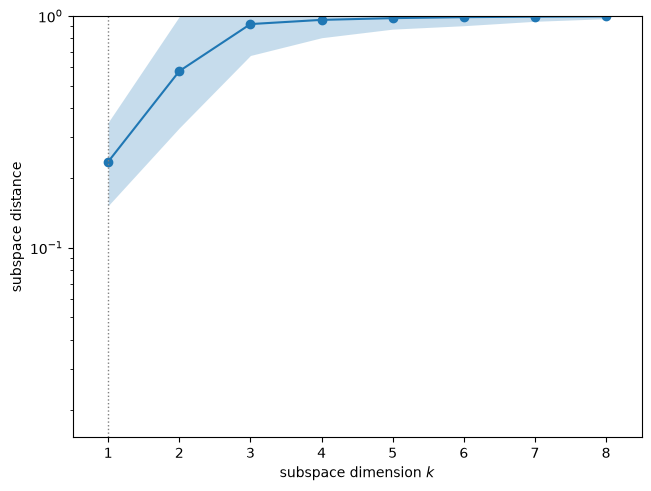

In [6]:
fig, ax = ac.plotting.plot_subspace_errors(q_mean, k_max=8)
plt.close(fig)
fig

The mean bootstrap distance is 0.23 for $n = 1$ and 0.58 for $n = 2$ (printed above): the first direction is well determined by 650 runs, the second much less so.

### Eigenvectors

U_bar QPHD w1, |w_j| > 0.15: eps_pos -0.17, Ds_pos +0.37, sigma_pos +0.89
U_bar QPHD w2, |w_j| > 0.15: cs_max_pos +0.16, L_pos +0.59, eps_pos -0.20, R_pos -0.19, Ds_pos +0.57, sigma_pos -0.36, Ds_neg +0.21
U(600) QPHD w1, |w_j| > 0.15: L_pos +0.19, eps_pos -0.20, Ds_pos +0.57, sigma_pos +0.74
U(600) QPHD w2, |w_j| > 0.15: L_pos +0.51, R_pos -0.17, Ds_pos +0.53, sigma_pos -0.59


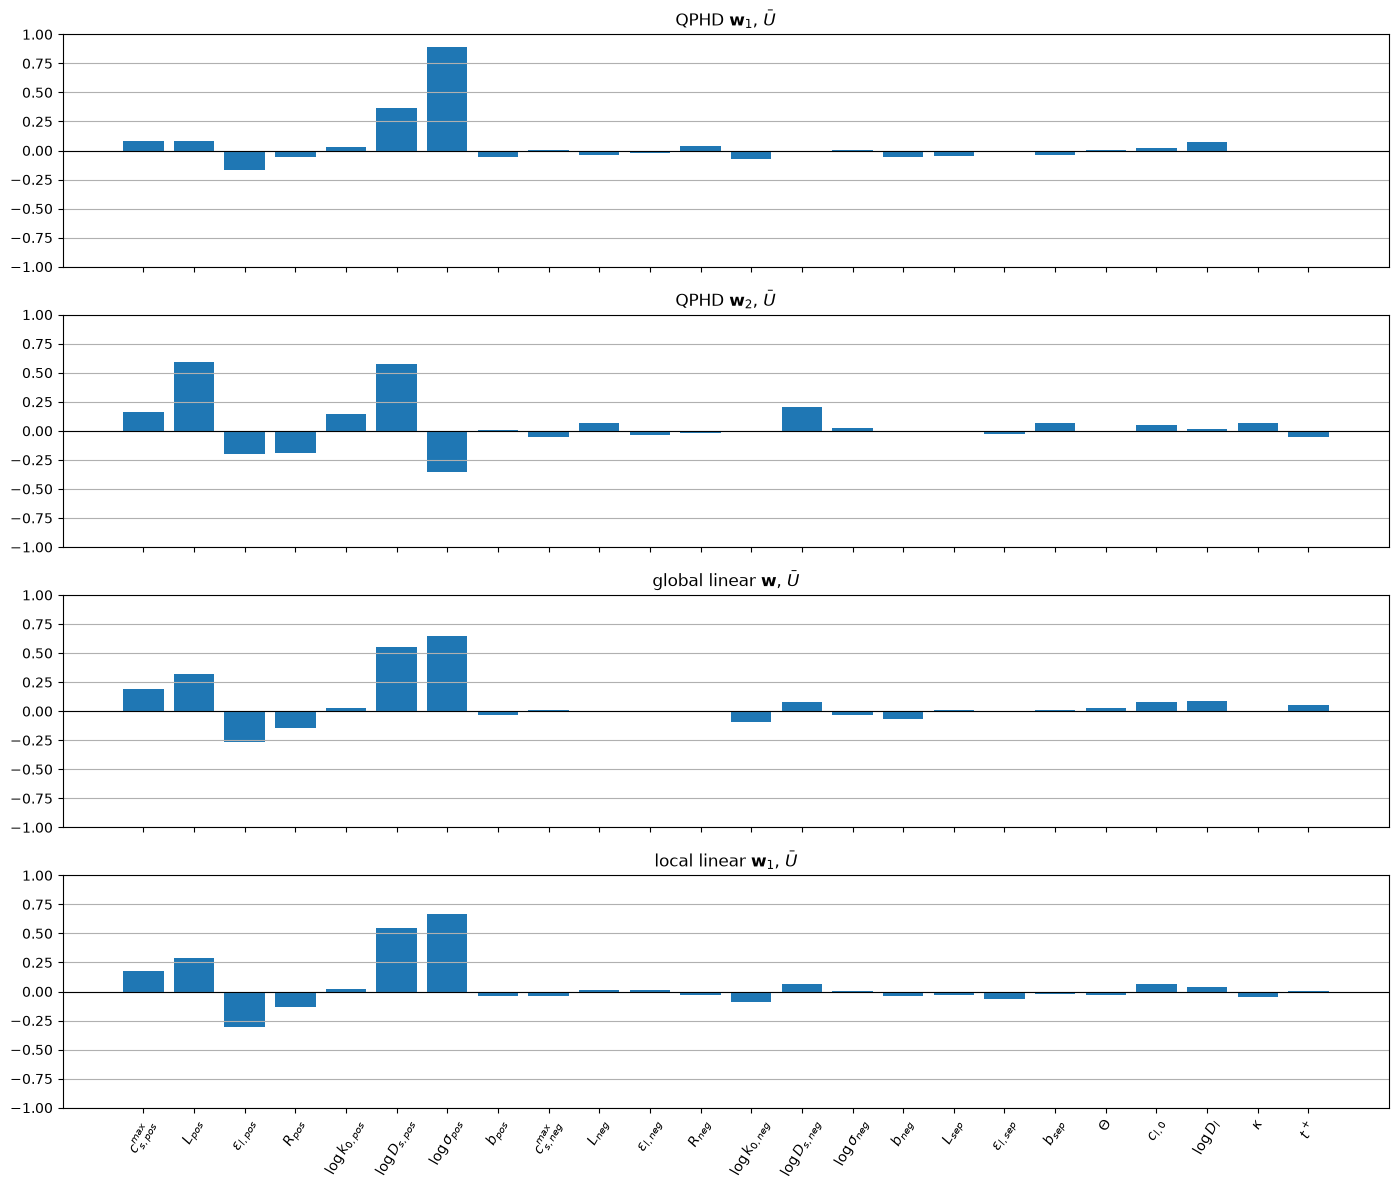

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
panels = [(q_mean.W[:, 0], r'QPHD $\mathbf{w}_1$, $\bar U$'), (q_mean.W[:, 1], r'QPHD $\mathbf{w}_2$, $\bar U$'),
          (ols_mean.W[:, 0], r'global linear $\mathbf{w}$, $\bar U$'), (opg_mean.W[:, 0], r'local linear $\mathbf{w}_1$, $\bar U$')]
for ax, (w, title) in zip(axes, panels):
    ax.bar(np.arange(m), w, color='C0')
    ax.axhline(0, color='k', lw=0.8); ax.set_ylim(-1, 1); ax.grid(True, axis='y'); ax.set_title(title)
axes[-1].set_xticks(np.arange(m)); axes[-1].set_xticklabels(labels, rotation=60)
fig.tight_layout()
for name, q in [('U_bar', q_mean), ('U(600)', q_end)]:
    for k in (0, 1):
        w = q.W[:, k]
        print(f'{name} QPHD w{k + 1}, |w_j| > 0.15:', ', '.join(f'{dfn.NAMES[j]} {w[j]:+.2f}' for j in np.flatnonzero(np.abs(w) > .15)))
plt.close(fig)
fig

In every estimate for $\bar U$ the largest weights are on $\log\sigma_{pos}$ and $\log D_{s,pos}$; the capacity-related inputs of the positive electrode follow with the signs physics expects (positive for $L_{pos}$ and $c^{\max}_{s,pos}$, negative for $\epsilon_{l,pos}$: a thicker, denser, less porous electrode has more capacity and loses less voltage). The second QPHD direction for $\bar U$ combines $L_{pos}$ (+0.59) and $\log D_{s,pos}$ (+0.57) against $\log\sigma_{pos}$ (−0.36). For $U(600)$ the two directions share their weight more evenly between $\log\sigma_{pos}$, $\log D_{s,pos}$ and $L_{pos}$ (printed lists). No input of the negative electrode, separator or electrolyte has a weight above 0.25 in either QPHD direction for either QoI.

### Sufficient summary plots

U_bar: corr(w1^T x, f) = 0.612
U(600): corr(w1^T x, f) = 0.591


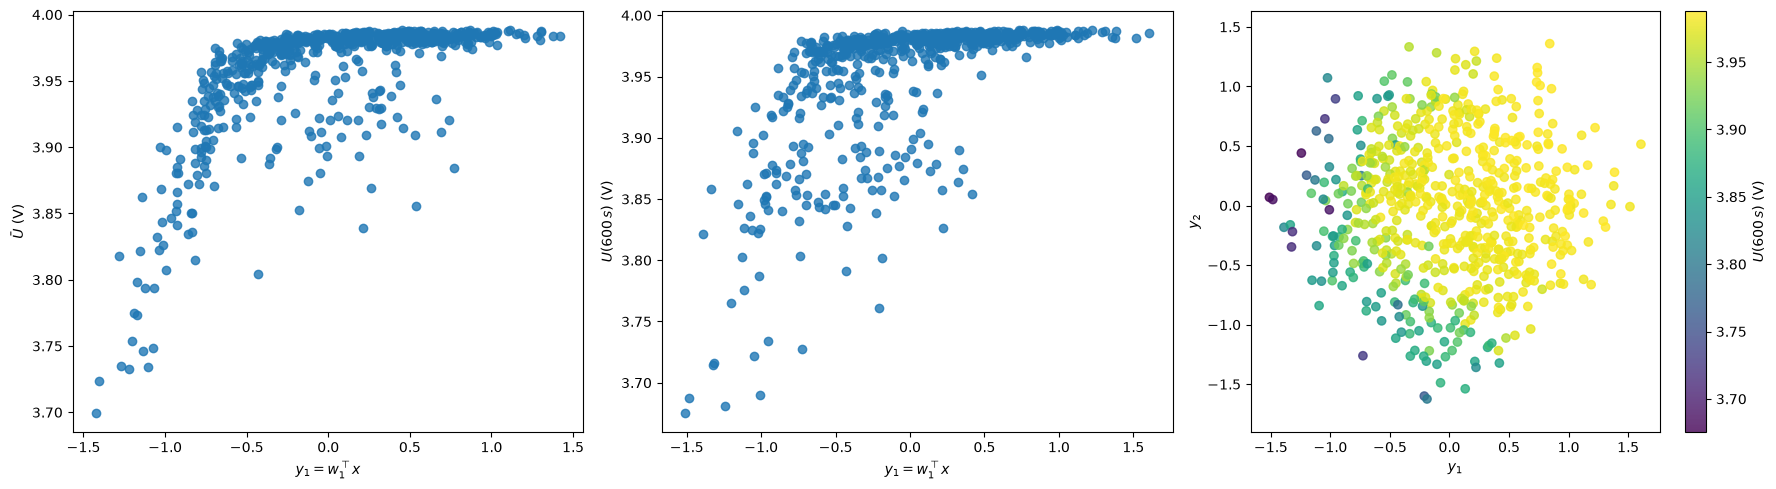

In [8]:
q_end2 = ac.with_dimension(q_end, 2)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ac.plotting.plot_sufficient_summary(q_mean, X=Z, f=f_mean, dims=1, qoi_label=r'$\bar U$ (V)', ax=axes[0])
ac.plotting.plot_sufficient_summary(q_end, X=Z, f=f_end, dims=1, qoi_label=r'$U(600\,s)$ (V)', ax=axes[1])
ac.plotting.plot_sufficient_summary(q_end2, X=Z, f=f_end, dims=2, qoi_label=r'$U(600\,s)$ (V)', ax=axes[2])
fig.tight_layout()
for name, q, f in [('U_bar', q_mean, f_mean), ('U(600)', q_end, f_end)]:
    y = space.to_normalized(Z) @ q.W[:, 0]
    print(f'{name}: corr(w1^T x, f) = {np.corrcoef(y, f)[0, 1]:.3f}')
plt.close(fig)
fig

$\bar U$ against $\mathbf w_1^T\mathbf x$ is a monotone, curved trend: flat near the starting voltage for large values of the active variable (high conductivity and diffusivity) and falling steeply below it, down to the lowest $\bar U$ of 3.70 V. Below the main branch, a band of lower values extends across the middle of the range of $\mathbf w_1^T\mathbf x$ (the correlation of $\bar U$ with $\mathbf w_1^T\mathbf x$ is only 0.61). The scatter is larger for $U(600)$, and its two-dimensional plot shows the low values at small $y_1$ and small $y_2$: the second direction carries much of that band.

### Surrogates on the active variables

U_bar: degree-3 polynomial in 1 active variable(s): LOO R^2 = 0.699
U_bar: degree-2 polynomial in 2 active variable(s): LOO R^2 = 0.751
U(600): degree-3 polynomial in 1 active variable(s): LOO R^2 = 0.515
U(600): degree-2 polynomial in 2 active variable(s): LOO R^2 = 0.692


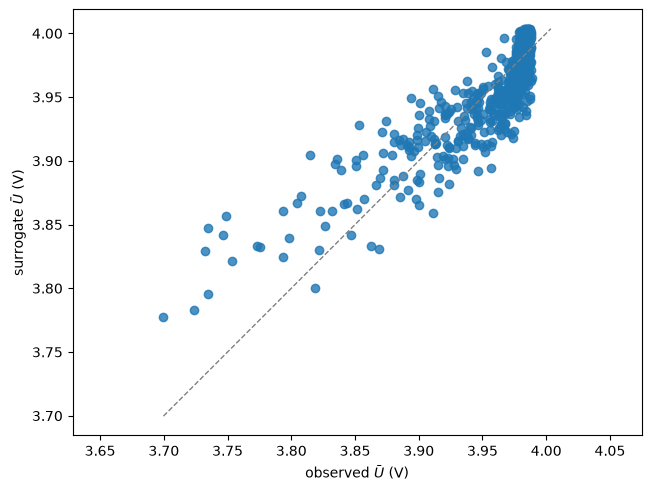

In [9]:
fits = [('U_bar', q_mean, f_mean, 1, 3), ('U_bar', ac.with_dimension(q_mean, 2), f_mean, 2, 2),
        ('U(600)', q_end, f_end, 1, 3), ('U(600)', q_end2, f_end, 2, 2)]
surs = {}
for name, q, f, n, deg in fits:
    s = ac.fit_surrogate(X=Z, f=f, subspace=q, kind='poly', degree=deg)
    surs[(name, n)] = s
    print(f'{name}: degree-{deg} polynomial in {n} active variable(s): LOO R^2 = {s.loo_r_squared:.3f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs[('U_bar', 2)], X=Z, f=f_mean, qoi_label=r'$\bar U$ (V)')
plt.close(fig)
fig

A cubic in $\mathbf w_1^T\mathbf x$ predicts $\bar U$ with leave-one-out $R^2 = 0.70$, and a quadratic in two active variables with 0.75, better than the full 325-term quadratic in all 24 inputs (0.46). For $U(600)$ the second variable matters more: 0.51 with one, 0.69 with two. The remaining variance sits in directions that QPHD at this sample size does not resolve.

### Does the result depend on the design size?

The first version of this data set had only the first 116 runs. The leading direction from those runs (global linear, the only estimator they allowed) against the QPHD direction from all 650:

In [10]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    o116 = ac.active_subspace(space=space, X=Z[:116], f=f_mean[:116], estimator='ols')
w116, w650 = o116.W[:, 0], q_mean.W[:, 0]
print(f'|w_OLS(116) . w1_QPHD(650)| = {abs(w116 @ w650):.3f}; |w_OLS(116) . w_OLS(650)| = {abs(w116 @ ols_mean.W[:, 0]):.3f}')
for nm in ['sigma_pos', 'Ds_pos', 'L_pos', 'eps_pos', 'cs_max_pos', 'R_pos']:
    j = dfn.NAMES.index(nm)
    print(f'  {nm:10s}  OLS(116) {w116[j]:+.2f}   OLS(650) {ols_mean.W[j, 0]:+.2f}   QPHD w1(650) {w650[j]:+.2f}')

|w_OLS(116) . w1_QPHD(650)| = 0.842; |w_OLS(116) . w_OLS(650)| = 0.948
  sigma_pos   OLS(116) +0.61   OLS(650) +0.65   QPHD w1(650) +0.89
  Ds_pos      OLS(116) +0.49   OLS(650) +0.55   QPHD w1(650) +0.37
  L_pos       OLS(116) +0.30   OLS(650) +0.32   QPHD w1(650) +0.08
  eps_pos     OLS(116) -0.23   OLS(650) -0.27   QPHD w1(650) -0.17
  cs_max_pos  OLS(116) +0.20   OLS(650) +0.20   QPHD w1(650) +0.08
  R_pos       OLS(116) -0.07   OLS(650) -0.14   QPHD w1(650) -0.05


The global linear direction barely moves between 116 and 650 runs ($|\mathbf w_{116}^T\mathbf w_{650}| = 0.95$), with $\log\sigma_{pos}$ and $\log D_{s,pos}$ first in both, and the QPHD first eigenvector from 650 runs puts even more weight on $\log\sigma_{pos}$ (+0.89). The disagreement with the paper (next section) is therefore not a small-sample artefact.

### The voltage at five times

The paper's point is that sensitivities change along the cycle. Here is the QPHD subspace of $U(t)$ at five times (no bootstrap). ($U(0)$ is the same for every sample by construction.)

   t   std U(t)   l1/l2   l2/l3   |w1(t).w1(U_bar)|   largest weights in w1(t)
  60   0.0390    8.22    2.48        0.953            sigma_pos +0.90, k0_pos +0.25, Ds_pos +0.22, eps_pos -0.18


 150   0.0430   13.36    1.59        0.993            sigma_pos +0.92, Ds_pos +0.29, eps_pos -0.16, k0_pos +0.09


 300   0.0734    6.86    1.99        0.969            sigma_pos +0.91, Ds_pos +0.26, k0_pos +0.22, eps_pos -0.15


 450   0.0636    3.36    4.84        0.999            sigma_pos +0.88, Ds_pos +0.38, eps_pos -0.17, L_pos +0.10


 600   0.0532    1.97    5.60        0.958            sigma_pos +0.74, Ds_pos +0.57, eps_pos -0.20, L_pos +0.19


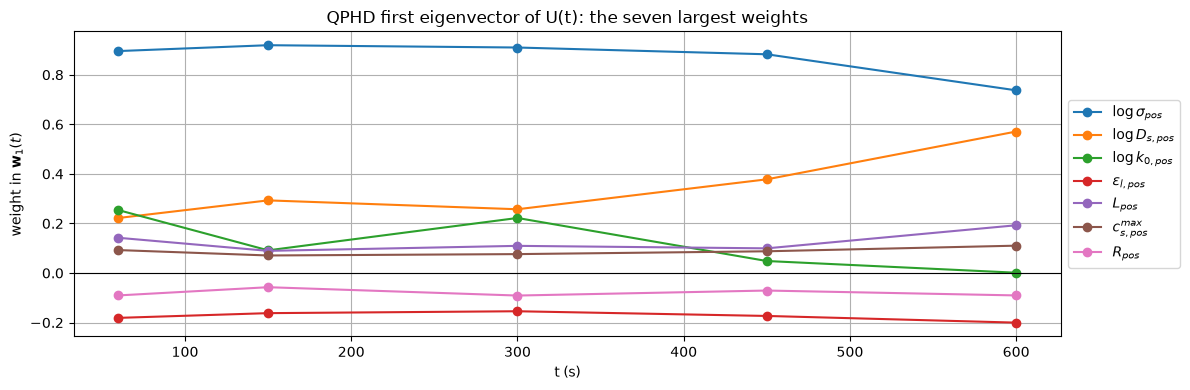

In [11]:
times = [60, 150, 300, 450, 600]
print('   t   std U(t)   l1/l2   l2/l3   |w1(t).w1(U_bar)|   largest weights in w1(t)')
W_t = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    for tt in times:
        s = ac.active_subspace(space=space, X=Z, f=V[:, tt], estimator='qphd')
        s = ac.orient(s, by='covariance', X=Z, f=V[:, tt], columns=1)
        lam = s.eigenvalues
        W_t.append(s.W[:, 0])
        print(f'{tt:4d}   {V[:, tt].std():.4f}   {lam[0] / lam[1]:5.2f}   {lam[1] / lam[2]:5.2f}        {abs(s.W[:, 0] @ q_mean.W[:, 0]):.3f}'
              f'            {top(s.W[:, 0], 4)}')
W_t = np.array(W_t)
fig, ax = plt.subplots(figsize=(12, 4))
for j in np.argsort(-np.abs(W_t).max(0))[:7]:
    ax.plot(times, W_t[:, j], 'o-', label=labels[j])
ax.axhline(0, color='k', lw=0.8); ax.set_xlabel('t (s)'); ax.set_ylabel(r'weight in $\mathbf{w}_1(t)$'); ax.grid(True)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)); ax.set_title('QPHD first eigenvector of U(t): the seven largest weights')
fig.tight_layout()
plt.close(fig)
fig

$\log\sigma_{pos}$ has the largest weight at all five times (0.88–0.92 up to 450 s, 0.74 at 600 s), while the weight of $\log D_{s,pos}$ grows from 0.22 at 60 s to 0.57 at 600 s, and the positive reaction rate constant appears early (0.25 at 60 s). The gap $\lambda_1/\lambda_2$ is largest mid-cycle (13.4 at 150 s) and smallest at the end (1.97 at 600 s), where a second direction appears ($\lambda_2/\lambda_3 = 5.60$). The spread of $U(t)$ is largest at 300 s (standard deviation 0.073 V).

## Comparison with the paper

The paper reports generalized Sobol' indices of the voltage curve, not active subspaces, so the comparison is qualitative. The activity scores $\alpha_j = \sum_i \lambda_i w_{ij}^2$ of the QPHD estimate are derivative-based importance measures that can be ranked against the paper's total-order indices (Fig. 8a, values read from the figure).

In [12]:
lam, W = q_mean.eigenvalues, q_mean.W
alpha = (W ** 2) @ np.clip(lam, 0, None)
alpha = alpha / alpha.sum()
rank = np.argsort(-alpha)
print('normalized activity scores (QPHD, U_bar), top 8:', ', '.join(f'{dfn.NAMES[j]} {alpha[j]:.2f}' for j in rank[:8]))
paper_total = {'L_pos': 0.39, 'eps_pos': 0.33, 'R_pos': 0.12, 'cs_max_pos': 0.11}   # read from Fig. 8a (PC, total order)
print("rank here of the paper's four leading inputs:",
      ', '.join(f'{k} #{int(np.flatnonzero(rank == dfn.NAMES.index(k))[0]) + 1}' for k in paper_total))
Cp = dfn.theoretical_capacity(X[:, 0], X[:, 1], X[:, 2]); Cn = dfn.theoretical_capacity(X[:, 8], X[:, 9], X[:, 10])
print(f'positive electrode limiting (C_theo,pos < C_theo,neg) in {np.mean(Cp < Cn):.0%} of samples; '
      f'largest peak C_theo-rate over the samples: {dfn.PEAK_CURRENT_DENSITY / np.minimum(Cp, Cn).min():.2f} 1/h')
print(f'U(t) mean / std at t = 300 s: {V[:, 300].mean():.3f} / {V[:, 300].std():.3f} V; '
      f'at t = 600 s: {V[:, 600].mean():.3f} / {V[:, 600].std():.3f} V')
print(f'R^2 of U_bar on log10 sigma_pos alone: {np.corrcoef(Z[:, 6], f_mean)[0, 1] ** 2:.2f}; '
      f'on log10 Ds_pos alone: {np.corrcoef(Z[:, 5], f_mean)[0, 1] ** 2:.2f}; on L_pos alone: {np.corrcoef(Z[:, 1], f_mean)[0, 1] ** 2:.2f}')

# What the comparison below rules out, and what it does not
print(f"paper's peak current density (about 2.85 A/m^2, read from Fig. 6e) / ours: {2.85 / dfn.PEAK_CURRENT_DENSITY:.3f}")
I = dfn.SCALE * dfn.US06[:, 1] / dfn.AREA                         # current density [A/m^2], discharge > 0
q_ah = np.concatenate([[0.0], np.cumsum(0.5 * (I[1:] + I[:-1]) * np.diff(dfn.T_EVAL))]) / 3600   # A h/m^2 drawn so far
print(f'charge drawn by the scaled cycle: net {q_ah[-1]:.4f} A h/m^2, largest running total {q_ah.max():.4f} A h/m^2 = '
      f'{q_ah.max() / dfn.C_THEO_MIN:.1%} of the smallest C_theo in the box ({dfn.C_THEO_MIN:.3f}), '
      f'{q_ah.max() / np.minimum(Cp, Cn).min():.1%} of the smallest among the samples ({np.minimum(Cp, Cn).min():.2f}); '
      f'{2 * q_ah.max() / dfn.C_THEO_MIN:.1%} of the half of the box minimum left above the half-charge start')
brug = (1 - np.array([dfn.UPPER[2], dfn.LOWER[2]])) ** 1.5
print(f'electrode Bruggeman factor (1 - eps_l,pos)^1.5 over the box: {brug[0]:.2f}-{brug[1]:.2f}, i.e. a shift of '
      f'log10 sigma_eff by at most {-np.log10(brug[0]):.2f} decades; log10 sigma_pos spans {np.log10(dfn.UPPER[6] / dfn.LOWER[6]):.2f} decades')
edges = np.linspace(np.log10(dfn.LOWER[6]), np.log10(dfn.UPPER[6]), 9)
b = np.clip(np.digitize(Z[:, 6], edges) - 1, 0, 7)
print('mean U_bar in 8 equal bins of log10 sigma_pos (bin centre: V):',
      ', '.join(f'{0.5 * (edges[k] + edges[k + 1]):+.1f}: {f_mean[b == k].mean():.3f}' for k in range(8)))
vmin = V.min(1); low = np.argsort(vmin)[:8]
print(f'the 8 lowest minimum voltages ({vmin[low].min():.2f}-{vmin[low].max():.2f} V) all have log10 sigma_pos in '
      f'[{Z[low, 6].min():.2f}, {Z[low, 6].max():.2f}] and log10 Ds_pos in [{Z[low, 5].min():.2f}, {Z[low, 5].max():.2f}]')
e_lo, e_hi = np.ones(m), np.ones(m)                               # only the log-uniform entries are used
e_lo[dfn.LOG], e_hi[dfn.LOG] = np.exp(np.log10(dfn.LOWER[dfn.LOG])), np.exp(np.log10(dfn.UPPER[dfn.LOG]))
print('if log10 bounds are read as natural-log bounds (support e^lo..e^hi):',
      ', '.join(f'{dfn.NAMES[j]} {e_lo[j]:.2g}-{e_hi[j]:.2g}' for j in np.flatnonzero(dfn.LOG)))
fast = (X[:, 6] >= e_lo[6]) & (X[:, 5] >= 1e-13)
print(f'samples here with sigma_pos >= {e_lo[6]:.2g} S/m and Ds_pos >= 1e-13 m^2/s: {fast.sum()}, std of U_bar {1000 * f_mean[fast].std():.1f} mV '
      f'(all samples: {1000 * f_mean.std():.1f} mV)')

normalized activity scores (QPHD, U_bar), top 8: sigma_pos 0.55, Ds_pos 0.14, L_pos 0.06, eps_pos 0.03, k0_pos 0.02, b_sep 0.02, R_pos 0.02, cs_max_pos 0.02
rank here of the paper's four leading inputs: L_pos #3, eps_pos #4, R_pos #7, cs_max_pos #8
positive electrode limiting (C_theo,pos < C_theo,neg) in 61% of samples; largest peak C_theo-rate over the samples: 1.37 1/h
U(t) mean / std at t = 300 s: 3.933 / 0.073 V; at t = 600 s: 3.954 / 0.053 V
R^2 of U_bar on log10 sigma_pos alone: 0.20; on log10 Ds_pos alone: 0.15; on L_pos alone: 0.05
paper's peak current density (about 2.85 A/m^2, read from Fig. 6e) / ours: 1.053
charge drawn by the scaled cycle: net 0.0469 A h/m^2, largest running total 0.0493 A h/m^2 = 3.6% of the smallest C_theo in the box (1.353), 2.5% of the smallest among the samples (1.97); 7.3% of the half of the box minimum left above the half-charge start
electrode Bruggeman factor (1 - eps_l,pos)^1.5 over the box: 0.21-0.75, i.e. a shift of log10 sigma_eff by at most 0

| quantity | paper | this notebook |
|---|---|---|
| leading inputs | $L_{pos}$, $\epsilon_{l,pos}$, $R_{pos}$, $c^{\max}_{s,pos}$ (total-order ≈ 0.39, 0.33, 0.12, 0.11, read from Fig. 8a) | activity scores: $\sigma_{pos}$ 0.55, $D_{s,pos}$ 0.14, $L_{pos}$ 0.06, $\epsilon_{l,pos}$ 0.03; $R_{pos}$ and $c^{\max}_{s,pos}$ rank 7th and 8th (0.02) |
| $\sigma_{pos}$, $D_{s,pos}$ | total-order ≈ 0 (Fig. 8a); "the effect of the solid diffusivity seems negligible" (p. 14) | first and second in every estimate, at every time |
| positive electrode limiting | "around 60 %" (Fig. 6) | 61 % of 650 samples |
| mean $U$ at 300 s / 600 s | ≈ 3.95 / 3.95 V (read from Fig. 7a) | 3.933 / 3.954 V |
| std of $U$ | band of roughly ±0.05–0.1 V (Fig. 7a) | 0.073 V at 300 s, 0.053 V at 600 s |
| lowest voltages | some runs near 2 V among 500 plotted (Fig. 7b) | 3.36 V (650 runs) |
| failed runs | ≤ 0.003 % of 100,000 (p. 7) | 0 of 650 |
| active subspace | not reported | QPHD $\lambda_1/\lambda_2 = 5.07$ for $\bar U$ (bootstrap 2.25–5.46), $\lambda_2/\lambda_3 = 3.48$; 1-variable LOO $R^2 = 0.70$, 2-variable 0.75 |

**The main disagreement.** In this rebuild the positive electrode's electronic conductivity $\sigma_{pos}$ and solid diffusivity $D_{s,pos}$ lead the active direction at every time and for both QoIs ($\log\sigma_{pos}$ alone explains $R^2 = 0.20$ of $\bar U$, more than any other single input), while the paper finds both negligible and ranks $L_{pos}$, $\epsilon_{l,pos}$, $R_{pos}$ and $c^{\max}_{s,pos}$ first. The disagreement is the same with 116 runs and with 650. It is a property of the model as implemented here, not of the estimator: one-at-a-time changes at the centre of the box lower $\bar U$ by 0.134 V when $\sigma_{pos}$ goes from its upper to its lower bound, by 0.012 V for $D_{s,pos}$, 0.029 V for $L_{pos}$ and 0.004 V for $R_{pos}$ (`python generate_data.py --oat`, output in `DATA.md`, "Accuracy"). Table A.2 lets $\sigma_{pos}$ go down to $5.2\times10^{-6}$ S m⁻¹ and $D_{s,pos}$ to $9.6\times10^{-19}$ m² s⁻¹, values at which electronic conduction and solid diffusion in the positive electrode do limit the cell under this current. The capacity-related inputs matter here too, with the expected signs, and the share of samples with a limiting positive electrode agrees with the paper.

**Two choices that do not explain it.**

- *The current factor.* The paper's peak current density is about 1.053 times ours (printed above). To first order, both the overpotentials and the charge drawn scale linearly with the current, so a 5 % larger factor cannot reorder the inputs.
- *An electrode Bruggeman factor on $\sigma$.* PyBaMM's factor $(1-\epsilon_{l,pos})^{1.5}$ (kept here) lies in 0.21–0.75 over the box. It shifts $\log_{10}\sigma_{\mathrm{eff}}$ by at most 0.68 of the 8.28 decades that $\sigma_{pos}$ spans. The effect of $\sigma_{pos}$ on $\bar U$ sits in the lowest two to three decades: the binned means printed above rise from 3.880 V to 3.947 V and 3.972 V over the first three of eight bins, then stay at 3.969–3.974 V. A shift of at most 0.7 decade leaves that region inside the box.

**The paper's dips to about 2 V.** They are not deep discharges. The scaled cycle draws at most 0.0493 A h m⁻², which is 3.6 % of the smallest $C_\mathrm{theo}$ anywhere in the box and 2.5 % of the smallest among our samples (7.3 % even of the half of the box minimum that lies above the half-charge start). So no sample can be discharged through its capacity, and short dips to about 2 V (Fig. 7b) must be transient overpotentials. Here, the eight lowest minimum voltages all come with $\log_{10}\sigma_{pos} \le -4.09$ and $\log_{10} D_{s,pos} \le -15.37$, that is, with transport limits in the positive electrode. If the same holds in the paper's runs, its *simulations* contain strong effects of the inputs that its *indices* rate ≈ 0, and the gap would lie in how the variance is attributed. Why none of our 650 runs goes below 3.36 V is itself open.

**Two possible causes, unconfirmed.** Both come from reading the authors' TDGSA code (https://github.com/ezonta/TDGSA, commit 6f5e78e). Both act specifically on the log-uniform inputs. In Fig. 8a, $D_{s,pos}$, $k_{0,neg}$ and $D_{s,neg}$ have no visible bar and $k_{0,pos}$ and $\sigma_{pos}$ only slivers, while uniform inputs with little expected effect (e.g. $\Theta$, $L_{neg}$, $L_{sep}$) show small bars. Neither can be confirmed without the authors' 24-input script; both are questions for the authors in `DATA.md`.

1. *Log-uniform bounds.* `TDGSA/utils.py` (lines 44–45) passes the `[lo, hi]` given for a `"loguniform"` input straight to `chaospy.LogUniform(lo, hi)`. chaospy defines that distribution on $[e^{lo}, e^{hi}]$ (`distributions/collection/log_uniform.py`, lines 19–26, the same in 4.3.13, which TDGSA pins, and in 4.3.21), so it expects natural-log bounds. The values of Table A.2 cannot have been passed as they stand, because the upper bound of $\sigma_{pos}$ would become $e^{1000}$. If $\log_{10}$ bounds were passed, the effective ranges would be those printed above (e.g. $\sigma_{pos}$ 0.0051–20 S m⁻¹, $D_{s,pos}$ 1.5e-8–9.2e-6 m² s⁻¹), and both inputs would be inert. But this would also shrink the spread of $\bar U$ to a few mV: our 102 samples with fast positive-electrode conduction and diffusion have a standard deviation of 3.0 mV, against 46.0 mV for all samples. That conflicts with the spread and the dips in the paper's Fig. 7, so this is at most part of the story.
2. *A polynomial chaos basis in physical units.* `TDGSA/core.py` (lines 347–354 and 490–497) builds the expansion with `cp.generate_expansion(order, joint_dist, normed=True, ...)`, where the default three-term recurrence gives polynomials orthogonal in the *physical* variable under the log-uniform density. Over 6–8 decades, such polynomials cannot resolve effects confined to the lower decades, and the surrogate then misses variance. The paper's own remark (p. 8) that the KL eigenvalue variance and the PC variance can differ by more than 10 % is consistent with this. An emulation on our data (`DATA.md`) lowers the index of $\sigma_{pos}$ but not that of $D_{s,pos}$, so this too would explain only part of the gap.

## References

1. E. Zonta, I. Jovanovic Buha, M. Spinola, C. Weißinger, H.-J. Bungartz, A. Jossen. Time-dependent global sensitivity analysis of the Doyle–Fuller–Newman model. *Journal of Energy Storage* 158 (2026) 121751. [doi:10.1016/j.est.2026.121751](https://doi.org/10.1016/j.est.2026.121751). Preprint arXiv:2502.17275v2. Code: <https://github.com/ezonta/TDGSA> (BSD-3-Clause).
2. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
3. P. G. Constantine, A. Doostan. Time-dependent global sensitivity analysis with active subspaces for a lithium ion battery model. *Statistical Analysis and Data Mining* 10(5) (2017) 243–262. [doi:10.1002/sam.11347](https://doi.org/10.1002/sam.11347).
4. V. Sulzer, S. G. Marquis, R. Timms, M. Robinson, S. J. Chapman. Python Battery Mathematical Modelling (PyBaMM). *Journal of Open Research Software* 9(1) (2021) 14. [doi:10.5334/jors.309](https://doi.org/10.5334/jors.309).
5. S. G. Marquis, V. Sulzer, R. Timms, C. P. Please, S. J. Chapman. An asymptotic derivation of a single particle model with electrolyte. *Journal of The Electrochemical Society* 166(15) (2019) A3693–A3706. [doi:10.1149/2.0341915jes](https://doi.org/10.1149/2.0341915jes).
6. M. Doyle, T. F. Fuller, J. Newman. Modeling of galvanostatic charge and discharge of the lithium/polymer/insertion cell. *Journal of The Electrochemical Society* 140(6) (1993) 1526–1533. [doi:10.1149/1.2221597](https://doi.org/10.1149/1.2221597).

## Acknowledgments

From the paper: "This work is supported by Capgemini in the context of the TUM-Capgemini Research and Development Agreement 'Innovative and non-invasive methods of parameter identification for lithium-ion battery models'."